In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score

**Load the dataset**

In [ ]:
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target   # median house value in $100,000s

print("Shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())
X.head()

Shape: (20640, 8)
Missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


**EDA**

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


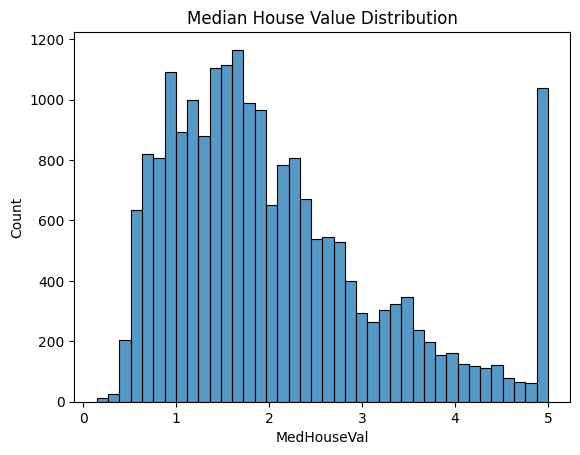

In [ ]:
display(X.describe())
sns.histplot(y, bins=40)
plt.title("Median House Value Distribution")
plt.show()

**Split the data**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (16512, 8) Test: (4128, 8)


**Preprocessing with ColumnTransformer**

In [ ]:
num_features = X.columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[("num", StandardScaler(), num_features)]
)

**Building  the pipeline**

In [ ]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("knn", KNeighborsRegressor())
])

**The GridSearchCV**

In [ ]:
param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

grid = GridSearchCV(
    pipeline, param_grid, cv=5, scoring="r2", n_jobs=-1, verbose=1
)
grid.fit(X_train, y_train)

Fitting 5 folds for each of 16 candidates, totalling 80 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['MedInc',
                                                                          'HouseAge',
                                                                          'AveRooms',
                                                                          'AveBedrms',
                                                                          'Population',
                                                                          'AveOccup',
                                                                          'Latitude',
                                                                          'Longitude'])])),
                                       ('knn', KNeighborsRegressor())]),
             n_jobs=-1,
             param_grid={'knn__n_neighbors': [3, 5, 7, 9], 'knn__p': [1, 2],
                         'knn__weights': ['uniform', 'distance']},
             scoring='r2', verbose=1)

**The parameters and test evaluation**

In [ ]:
print("Best parameters:", grid.best_params_)
print("Best CV R²:", round(grid.best_score_, 4))

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)
print("Test R²:", round(r2_score(y_test, y_pred), 4))

Best parameters: {'knn__n_neighbors': 9, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV R²: 0.7313
Test R²: 0.7221


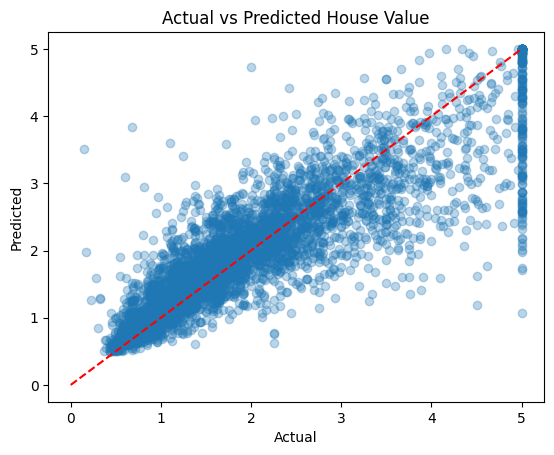

In [ ]:
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([0, 5], [0, 5], "r--")
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.title("Actual vs Predicted House Value")
plt.show()

**The saved pipeline**

In [ ]:
joblib.dump(best_model, "knn_housing_pipeline.joblib")

# Verify it loads and predicts
loaded = joblib.load("knn_housing_pipeline.joblib")
print("Reloaded test R²:", round(r2_score(y_test, loaded.predict(X_test)), 4))

Reloaded test R²: 0.7221


In [ ]:
from google.colab import files
files.download("knn_housing_pipeline.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>